# Exercise 3.1 — Hunting an Ultrasonic Secret Code

**The scenario.** Four suspicious audio files may hide a *four-number secret code*.
This time the code was not simply pasted into the audio: it was **amplitude-modulated
(AM)** onto an **ultrasonic carrier** (a frequency above human hearing, ~18–20 kHz) and
then mixed into an ordinary-sounding cover recording. Because the code lives above the
audible range, you hear nothing suspicious on normal playback.

This notebook walks the full investigation:

1. **Discovery** — open the files, inspect their format, look at their spectra.
2. **Detection** — measure ultrasonic energy to find the file that carries hidden data.
3. **Diagnosis** — zoom into the ultrasonic band and recognise the AM fingerprint (carrier + sidebands).
4. **Decoding** — demodulate the carrier back down to the audible range.
5. **Reveal** — plot and *play* the recovered code.

> A quick primer on the physics we'll use:
> AM transmission takes a message \(m(t)\) and multiplies it by a high-frequency carrier
> \(\cos(2\pi f_c t)\). In the frequency domain this **shifts** the message's spectrum up
> to sit around \(f_c\) (creating a carrier line with symmetric *sidebands*). To reverse it we
> detect the **envelope** of that band — which traces out \(m(t)\) again.

## 0 · Setup

In [1]:
import warnings
from pathlib import Path
import numpy as np
from scipy.io import wavfile
from scipy.signal import butter, sosfiltfilt, hilbert, spectrogram
import matplotlib.pyplot as plt
from IPython.display import Audio, display

plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["figure.dpi"] = 110

DATA = Path.cwd().parent / "assets" / "Ex3_files"
FILES = sorted(DATA.glob("Ex3_sound[1-4].wav"))
print("Found:", [f.name for f in FILES])

Found: ['Ex3_sound1.wav', 'Ex3_sound2.wav', 'Ex3_sound3.wav', 'Ex3_sound4.wav']


In [2]:
def load_wav(path):
    """Read a WAV as mono float64 in [-1, 1], plus its sample rate."""
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")          # stray non-data chunks
        sr, data = wavfile.read(path)
    if data.ndim > 1:
        data = data[:, 0]
    x = data.astype(np.float64)
    if np.issubdtype(data.dtype, np.integer):
        x /= np.iinfo(data.dtype).max
    return sr, x

## 1 · Discovery — what are we dealing with?

First just look at the container format. The **sample rate** is decisive here: a signal
sampled at \(f_s\) can only represent frequencies up to the *Nyquist limit* \(f_s/2\).
Truly ultrasonic content (say 19 kHz) needs headroom above it, so a 48 kHz file
(Nyquist 24 kHz) can hold it comfortably, while a 44.1 kHz file (Nyquist 22.05 kHz)
barely can.

In [3]:
print(f"{"file":<18}{"sample rate":>12}{"Nyquist":>10}{"duration":>11}")
print("-" * 51)
signals = {}
for f in FILES:
    sr, x = load_wav(f)
    signals[f.name] = (sr, x)
    print(f"{f.name:<18}{sr:>10} Hz{sr/2/1000:>8.1f}k{len(x)/sr:>9.2f}s")

file               sample rate   Nyquist   duration
---------------------------------------------------
Ex3_sound1.wav         44100 Hz    22.1k    16.00s
Ex3_sound2.wav         48000 Hz    24.0k    13.16s
Ex3_sound3.wav         48000 Hz    24.0k     5.91s
Ex3_sound4.wav         48000 Hz    24.0k     6.24s


### Look at the full spectrum of every file

If a file hides an ultrasonic carrier, it will show up as a conspicuous spike near the
top of its spectrum — a place where natural recordings usually have almost no energy.

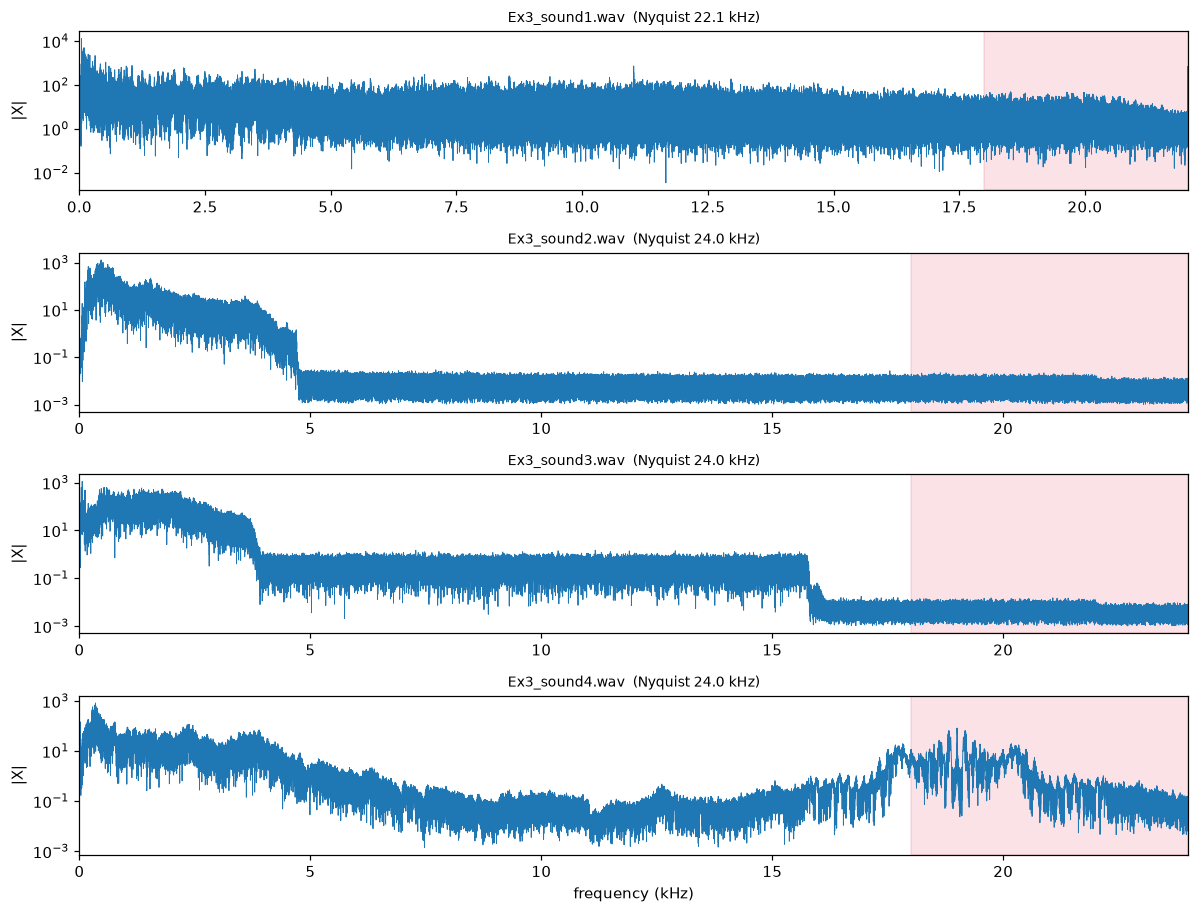

In [4]:
fig, axes = plt.subplots(len(FILES), 1, figsize=(11, 2.1*len(FILES)), sharex=False)
for ax, (name, (sr, x)) in zip(axes, signals.items()):
    mag = np.abs(np.fft.rfft(x * np.hanning(len(x))))
    freq = np.fft.rfftfreq(len(x), 1/sr)
    ax.semilogy(freq/1000, mag + 1e-3, lw=0.6)
    ax.axvspan(18, sr/2/1000, color="crimson", alpha=0.12)   # ultrasonic zone
    ax.set_title(f"{name}  (Nyquist {sr/2/1000:.1f} kHz)", fontsize=9)
    ax.set_ylabel("|X|"); ax.set_xlim(0, sr/2/1000)
axes[-1].set_xlabel("frequency (kHz)")
plt.tight_layout(); plt.show()

The red band marks the ultrasonic region (≥ 18 kHz). Most files decay into noise there —
but one of them has a clear bump. Let's turn that eyeball impression into a number.

## 2 · Detection — measure ultrasonic energy

For each file we compute the fraction of total spectral energy that lives at/above 18 kHz.
A clean recording spends a fraction of a percent up there; a file carrying an AM carrier
spends *far* more. (We skip the single Nyquist bin, which collects edge/aliasing junk on
the 44.1 kHz files.)

In [5]:
ULTRA = 18000.0
rows = []
for name, (sr, x) in signals.items():
    mag = np.abs(np.fft.rfft(x * np.hanning(len(x))))
    freq = np.fft.rfftfreq(len(x), 1/sr)
    m = (freq >= ULTRA) & (freq < sr/2 - 1.0)
    frac = mag[m].sum() / (mag.sum() + 1e-12)
    carrier = freq[m][np.argmax(mag[m])]
    rows.append((name, frac*100, carrier))

print(f"{"file":<18}{"ultrasonic energy":>20}{"peak freq":>12}")
print("-" * 50)
for name, pct, cf in rows:
    flag = "  <== SUSPICIOUS" if pct > 8 else ""
    print(f"{name:<18}{pct:>18.3f}%{cf:>10.0f}Hz{flag}")

file                 ultrasonic energy   peak freq
--------------------------------------------------
Ex3_sound1.wav                 4.246%     18523Hz
Ex3_sound2.wav                 0.014%     18638Hz
Ex3_sound3.wav                 0.006%     21074Hz
Ex3_sound4.wav                10.863%     19001Hz  <== SUSPICIOUS


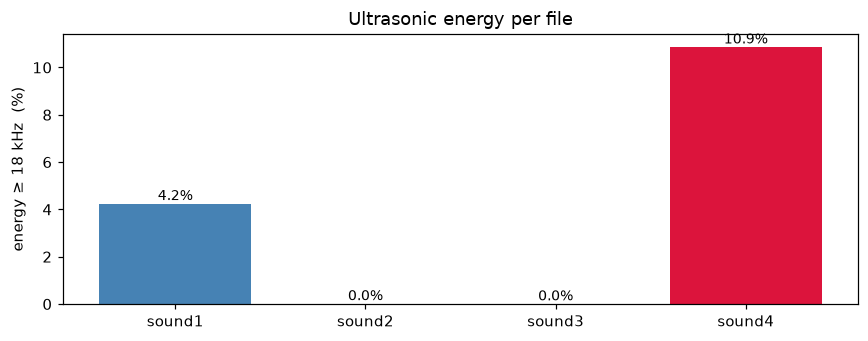

Suspicious file: Ex3_sound4.wav   estimated carrier ≈ 19001 Hz


In [6]:
names = [r[0].replace("Ex3_","").replace(".wav","") for r in rows]
pcts  = [r[1] for r in rows]
colors = ["crimson" if p > 8 else "steelblue" for p in pcts]
plt.figure(figsize=(8,3.2))
plt.bar(names, pcts, color=colors)
plt.ylabel("energy ≥ 18 kHz  (%)"); plt.title("Ultrasonic energy per file")
for i,p in enumerate(pcts): plt.text(i, p+0.15, f"{p:.1f}%", ha="center", fontsize=9)
plt.tight_layout(); plt.show()

suspect = max(rows, key=lambda r: r[1])
SUSPECT, CARRIER = suspect[0], suspect[2]
print(f"Suspicious file: {SUSPECT}   estimated carrier ≈ {CARRIER:.0f} Hz")

**Verdict:** one file dominates. That is where the hidden data lives, and the peak of
its ultrasonic energy gives us a first estimate of the **carrier frequency** \(f_c\).

## 3 · Diagnosis — is it really AM? Zoom into the carrier

Amplitude modulation leaves an unmistakable fingerprint: a **central carrier line** with
**symmetric sidebands** on either side. The sidebands are mirror images of the message
spectrum, shifted up by \(f_c\). If we see that structure, we've confirmed the method.

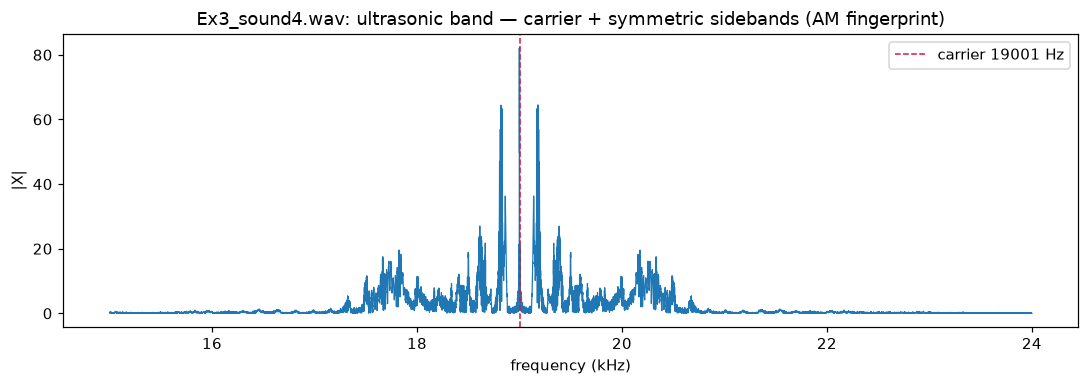

Refined carrier frequency: 19000.9 Hz


In [7]:
sr, x = signals[SUSPECT]
mag = np.abs(np.fft.rfft(x * np.hanning(len(x))))
freq = np.fft.rfftfreq(len(x), 1/sr)
sel = (freq >= 15000) & (freq <= sr/2)

plt.figure(figsize=(10,3.6))
plt.plot(freq[sel]/1000, mag[sel], lw=0.8)
plt.axvline(CARRIER/1000, color="crimson", ls="--", lw=1, label=f"carrier {CARRIER:.0f} Hz")
plt.title(f"{SUSPECT}: ultrasonic band — carrier + symmetric sidebands (AM fingerprint)")
plt.xlabel("frequency (kHz)"); plt.ylabel("|X|"); plt.legend()
plt.tight_layout(); plt.show()

# refine the carrier estimate to the exact peak bin
band = (freq > CARRIER-2000) & (freq < CARRIER+2000)
CARRIER = float(freq[band][np.argmax(mag[band])])
print(f"Refined carrier frequency: {CARRIER:.1f} Hz")

### When does the carrier switch on?

A spectrogram shows *time* on the x-axis. The hidden transmission should appear as a bright
horizontal streak at ~19 kHz that exists only while the code is being sent — separate from
the cover sound that fills the audible band.

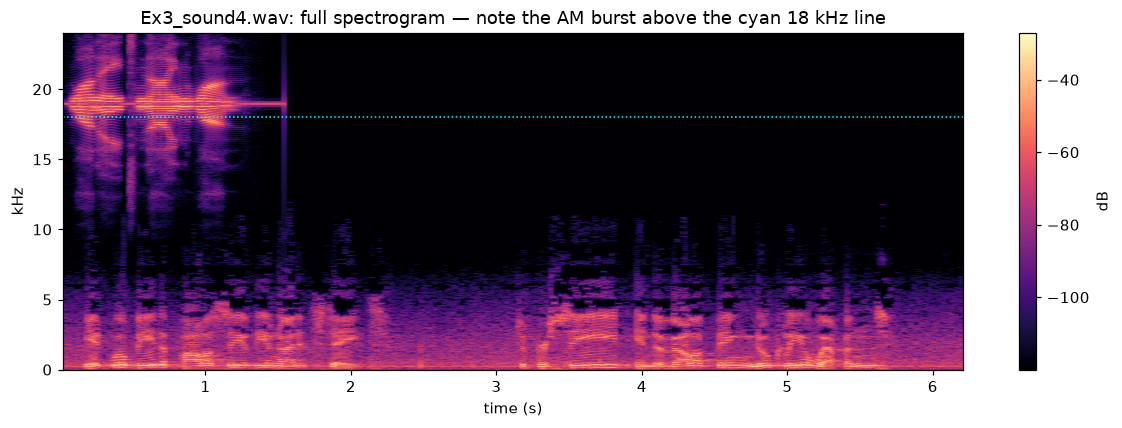

In [8]:
f, t, S = spectrogram(x, fs=sr, nperseg=2048, noverlap=1536)
plt.figure(figsize=(11,4))
plt.pcolormesh(t, f/1000, 10*np.log10(S+1e-12), shading="gouraud", cmap="magma")
plt.axhline(18, color="cyan", ls=":", lw=1)
plt.ylim(0, sr/2/1000); plt.colorbar(label="dB")
plt.title(f"{SUSPECT}: full spectrogram — note the AM burst above the cyan 18 kHz line")
plt.ylabel("kHz"); plt.xlabel("time (s)"); plt.tight_layout(); plt.show()

## 4 · Decoding — demodulate the carrier back to audible

Now we reverse the modulation. Three steps:

1. **Band-pass** a narrow window around \(f_c\) to isolate the AM signal from everything else.
2. **Envelope detection** — the modulated band is \(\big(1+m(t)\big)\cos(2\pi f_c t)\); its
   *envelope* is exactly the message. We get it from the magnitude of the **analytic signal**
   (a Hilbert transform), which strips away the carrier oscillation and leaves \(m(t)\).
3. **Low-pass** to keep only the audible code band and drop DC.

The result sits back in the 0–3.5 kHz range — audible again.

In [9]:
def demodulate(sr, x, fc, half_bw=2500.0, code_bw=3500.0):
    lo, hi = max(fc-half_bw, 100.0), min(fc+half_bw, sr/2-100.0)
    bp = butter(6, [lo, hi], btype="band", fs=sr, output="sos")
    band = sosfiltfilt(bp, x)                 # 1) isolate the carrier band
    env  = np.abs(hilbert(band))              # 2) envelope = the message
    env -= env.mean()                         #    remove DC
    lp = butter(6, code_bw, btype="low", fs=sr, output="sos")
    code = sosfiltfilt(lp, env)               # 3) keep the audible baseband
    return code / (np.max(np.abs(code)) + 1e-12)

code_sig = demodulate(sr, x, CARRIER)
print(f"Demodulated {len(code_sig)/sr:.2f}s of audio from the {CARRIER:.0f} Hz carrier.")

Demodulated 6.24s of audio from the 19001 Hz carrier.


### Look at what came back

The recovered baseband should look like **speech** — stacked harmonics (a voice) rather
than random noise — because someone is speaking the four numbers.

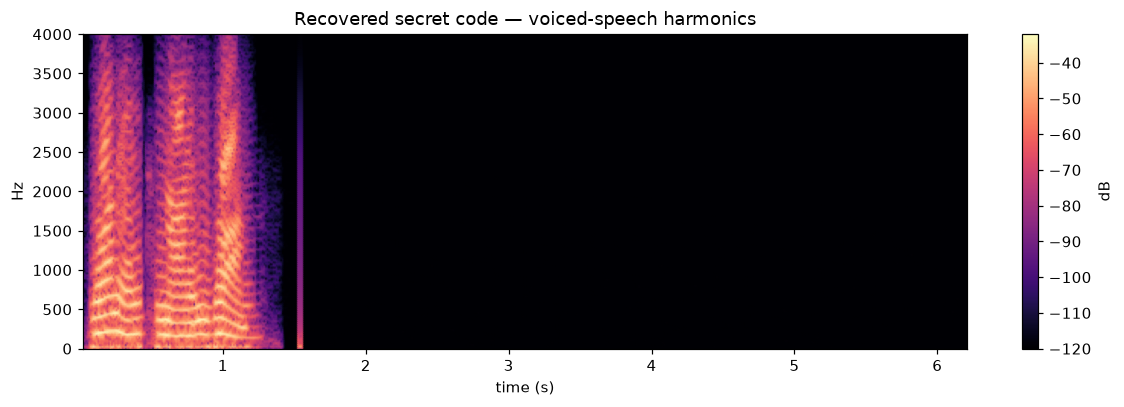

In [10]:
f, t, S = spectrogram(code_sig, fs=sr, nperseg=2048, noverlap=1536)
plt.figure(figsize=(11,3.8))
plt.pcolormesh(t, f, 10*np.log10(S+1e-12), shading="gouraud", cmap="magma")
plt.ylim(0, 4000); plt.title("Recovered secret code — voiced-speech harmonics")
plt.ylabel("Hz"); plt.xlabel("time (s)"); plt.colorbar(label="dB")
plt.tight_layout(); plt.show()

## 5 · Reveal — play the secret code

Press play. The four numbers are spoken in the first ~1.6 seconds.

In [11]:
out = Path.cwd() / "out"; out.mkdir(exist_ok=True)
wavfile.write(out / f"{SUSPECT.replace('.wav','')}_secret_code.wav",
              sr, (code_sig*0.9*32767).astype(np.int16))
print("Saved:", out / f"{SUSPECT.replace('.wav','')}_secret_code.wav")
display(Audio(code_sig, rate=sr))

Saved: /Users/davidcardozo/Documents/personal/uni/london-isp-midterm-ex3/app/out/Ex3_sound4_secret_code.wav


## Summary

| step | finding |
|------|---------|
| **Discovery** | 4 files (sounds 1–4); the three 48 kHz files (2–4) have room for ultrasonic content |
| **Detection** | **Ex3_sound4.wav** holds ~11% of its energy above 18 kHz — everything else < 0.02% (bar the 44.1 kHz edge artifact) |
| **Diagnosis** | ultrasonic band shows a carrier at **≈ 19 kHz** with symmetric sidebands → classic **AM** |
| **Decoding** | band-pass → Hilbert envelope → low-pass brings the code back to audible |
| **Reveal** | recovered audio is a voice speaking the **four-number secret code** |

The same logic is packaged as a command-line tool in
[`ultrasonic_decoder.py`](ultrasonic_decoder.py) — run `uv run ultrasonic_decoder.py`.